__Pergunta analítica__ <br>
Em quais horários, meses e períodos do ano o subsistema Nordeste apresentou episódios persistentes de exportação líquida e importação líquida entre 2023 e 2025, e como esses episódios se caracterizam quanto à geração eólica, fotovoltaica, carga e demais fontes?

__1. Biblioteca utilizadas__

In [2]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import funcoes

if "get_ipython" in globals():
    get_ipython().run_line_magic("matplotlib", "inline")

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("seaborn:", sns.__version__)
print("matplotlib:", plt.matplotlib.__version__)

Python: 3.11.9
pandas: 3.1.1
NumPy: 2.4.6
seaborn: 0.13.2
matplotlib: 3.11.2


__2. Base de dados__

In [3]:
PASTA = Path(".")
bd_balanco_2023 = PASTA / "BD/dadosBrutos/BALANCO_ENERGIA_SUBSISTEMA_2023.csv"
bd_balanco_2024 = PASTA / "BD/dadosBrutos/BALANCO_ENERGIA_SUBSISTEMA_2024.csv"
bd_balanco_2025 = PASTA / "BD/dadosBrutos/BALANCO_ENERGIA_SUBSISTEMA_2025.csv"

print("Arquivos disponíveis:", bd_balanco_2023.exists(), bd_balanco_2024.exists(), bd_balanco_2025.exists()) # debug

# Conversão de CSV para DataFrame
df_balanco_2023 = pd.read_csv(bd_balanco_2023, sep=";", encoding="utf-8")
# df_balanco_2023.head(3) # debug
# df_balanco_2023.info() # debug
df_balanco_2024 = pd.read_csv(bd_balanco_2024, sep=";", encoding="utf-8")
# df_balanco_2024.head(3) # debug
# df_balanco_2024.info() # debug
df_balanco_2025 = pd.read_csv(bd_balanco_2025, sep=";", encoding="utf-8")
# df_balanco_2025.head(3) # debug
# df_balanco_2025.info() # debug

Arquivos disponíveis: True True True


__3. Diagnóstico e preparação dos dados__

In [4]:
# # Concatenar os DataFrames em um único DataFrame
dados = pd.concat([df_balanco_2023, df_balanco_2024, df_balanco_2025], ignore_index=True)
# dados.head() # debug
dados.info() # debug
print("\n")

# # Checagem de dados ausentes, duplicados e distribuição por subsistema
chave_original = ["id_subsistema", "din_instante"]
print("Ausentes:", dados.isna().sum().sum())
print("Chaves duplicadas:", dados.duplicated(chave_original).sum())
print(dados.groupby("id_subsistema").size())
print("\n")
# # Tratamento dos códigos de subsistema
# identificar: que códigos chegaram?
print(f"Dados únicos em 'id_subsistema': {dados['id_subsistema'].unique()}")
print("\n")

# # Avaliação de geração/carga menor do que zero
colunas_geracao = ["val_gerhidraulica", "val_gertermica", "val_gereolica", "val_gersolar", "val_carga"]

for col in colunas_geracao:
    negativos = (dados[col] < 0).sum()
    print(f"{col}: {negativos} valores negativos")
print("\n")

# # corrigir: sem espaços e em maiúsculas
# # pelo resultado da análise, não há necessidade de corrigir os códigos de subsistema, pois todos estão corretos. 
# # Portanto, a linha de código abaixo foi comentada.
# dados["id_subsistema"] = dados["id_subsistema"].str.strip().str.upper()

# # Avaliação de outlier de carga:
# # SE tem a maior carga em termos de subsistema. Logo, compara-se N, S, NE com o mínimo de SE. Se tiver resultado maior, é outlier
# # SE não pode ter carga maior que o 1,5* mínimo do SIN. 
funcoes.outlier_carga(dados, "id_subsistema")

<class 'pandas.DataFrame'>
RangeIndex: 131520 entries, 0 to 131519
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id_subsistema      131520 non-null  str    
 1   nom_subsistema     131520 non-null  str    
 2   din_instante       131520 non-null  str    
 3   val_gerhidraulica  131520 non-null  float64
 4   val_gertermica     131520 non-null  float64
 5   val_gereolica      131520 non-null  float64
 6   val_gersolar       131520 non-null  float64
 7   val_carga          131520 non-null  float64
 8   val_intercambio    131520 non-null  float64
dtypes: float64(6), str(3)
memory usage: 9.0 MB


Ausentes: 0
Chaves duplicadas: 0
id_subsistema
N      26304
NE     26304
S      26304
SE     26304
SIN    26304
dtype: int64


Dados únicos em 'id_subsistema': <StringArray>
['NE', 'N', 'SIN', 'SE', 'S']
Length: 5, dtype: str


val_gerhidraulica: 0 valores negativos
val_gertermica: 0 valores negativos
val_gereo

__4. Manipulação dos dados__

In [5]:
# Mapeaar as colunas do DataFrame
mapa_nomes = {
    "id_subsistema": "SME",
    "nom_subsistema": "Subsistema",
    "din_instante": "Data-Hora",
    "val_gerhidraulica": "UHE",
    "val_gertermica": "UTE",
    "val_gereolica": "EOL",
    "val_gersolar": "UFV",
    "val_carga": "Carga",
    "val_intercambio": "Intercambio",
}
dados = dados.rename(columns=mapa_nomes).copy()
dados["Data-Hora"] = pd.to_datetime(dados["Data-Hora"]) # transforma coluna de texto para data
dados["Data"]  = dados["Data-Hora"].dt.date
dados["Ano"]  = dados["Data-Hora"].dt.year
dados["Mes"]  = dados["Data-Hora"].dt.month
dados["Dia"]  = dados["Data-Hora"].dt.day
dados["Hora"] = dados["Data-Hora"].dt.hour
dados["Dia-Semana"] = dados["Data-Hora"].dt.day_name()
dados["Dia-Hora"] = (
    dados["Dia"].astype(str).str.zfill(2)
    + "-"
    + dados["Hora"].astype(int).astype(str).str.zfill(2)
)
# print(dados.head()) # debug

# Estações do ano
dados["Estacao"] = dados["Mes"].map({
    1: "Verão", 2: "Verão", 3: "Verão",
    4: "Outono", 5: "Outono", 6: "Outono",
    7: "Inverno", 8: "Inverno", 9: "Inverno",
    10: "Primavera", 11: "Primavera", 12: "Primavera"
})

# Patamares
dados = funcoes.cria_patamar(dados)

# Ordenação das colunas
dados = dados[
    [
        "Data-Hora",
        "Data",
        "Ano",
        "Mes",
        "Dia",
        "Hora",
        "Dia-Hora",
        "Dia-Semana",
        "Patamar",
        "SME",
        "Subsistema",
        "UHE",
        "UTE",
        "EOL",
        "UFV",
        "Carga",
        "Intercambio",
        "Estacao"
    ]
]

# Separação por SME
dados_N   = dados[dados["SME"] == "N"].copy()
dados_S   = dados[dados["SME"] == "S"].copy()
dados_NE  = dados[dados["SME"] == "NE"].copy()
dados_SE  = dados[dados["SME"] == "SE"].copy()
dados_SIN = dados[dados["SME"] == "SIN"].copy()
# print(dados_SE.head()) # debug

# Agregação anual+mensal
dados_N_mensal   = funcoes.agrega_df_mensal(dados_N)
dados_S_mensal   = funcoes.agrega_df_mensal(dados_S)
dados_NE_mensal  = funcoes.agrega_df_mensal(dados_NE)
dados_SE_mensal  = funcoes.agrega_df_mensal(dados_SE)
dados_SIN_mensal = funcoes.agrega_df_mensal(dados_SIN)
# print(dados_N_mensal) # debug

dados_N.info() # debug

<class 'pandas.DataFrame'>
RangeIndex: 26304 entries, 1 to 131516
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Data-Hora    26304 non-null  datetime64[us]
 1   Data         26304 non-null  object        
 2   Ano          26304 non-null  int32         
 3   Mes          26304 non-null  int32         
 4   Dia          26304 non-null  int32         
 5   Hora         26304 non-null  int32         
 6   Dia-Hora     26304 non-null  str           
 7   Dia-Semana   26304 non-null  str           
 8   Patamar      26304 non-null  str           
 9   SME          26304 non-null  str           
 10  Subsistema   26304 non-null  str           
 11  UHE          26304 non-null  float64       
 12  UTE          26304 non-null  float64       
 13  EOL          26304 non-null  float64       
 14  UFV          26304 non-null  float64       
 15  Carga        26304 non-null  float64       
 16  Intercambio  2

__5. Análise exploratória__

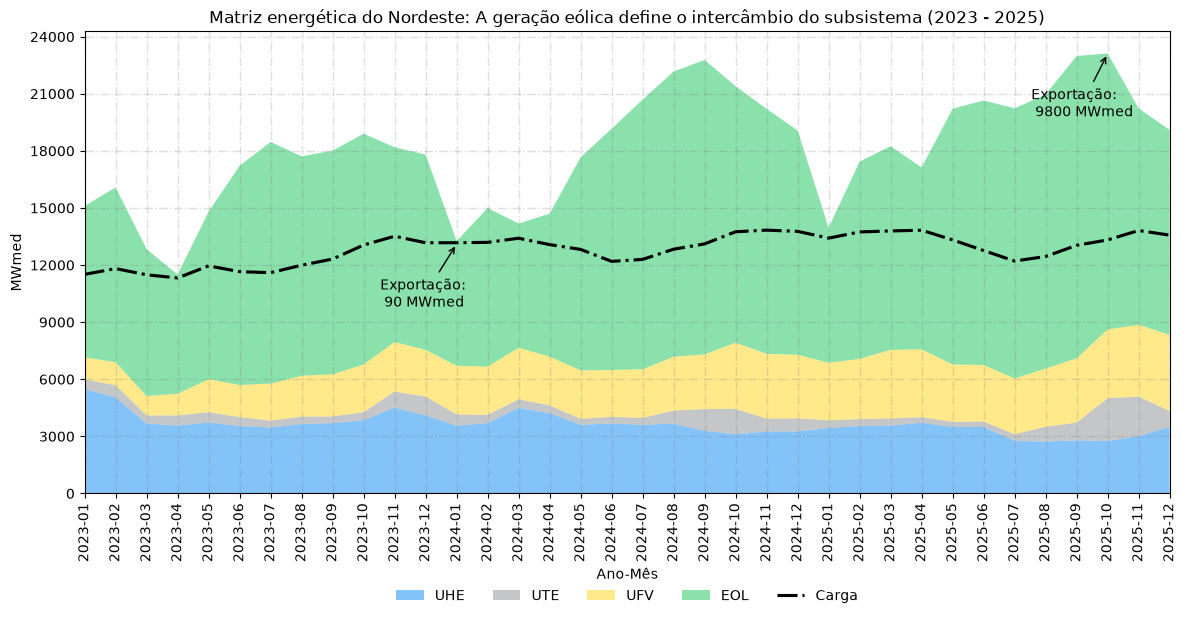

In [6]:
# # Análise do perfil da matriz energética do Nordeste   
# # Gráfico de áreas empilhadas (stackplot - fontes de energia) + linha (plot - carga)

fig, ax = plt.subplots(figsize=(14,6))

# print(dados_NE_mensal[["Ano-Mes","Intercambio","Carga","EOL"]].head(36)) # debug

ax.stackplot(
    dados_NE_mensal["Ano-Mes"],
    dados_NE_mensal["UHE"],
    dados_NE_mensal["UTE"],
    dados_NE_mensal["UFV"],
    dados_NE_mensal["EOL"],
    labels=["UHE", "UTE", "UFV", "EOL"],
    colors=["#0A89F1", "#8D8F91", "#FFD518E0", "#16C458"],
    alpha=0.5
)

ax.plot(
    dados_NE_mensal["Ano-Mes"],
    dados_NE_mensal["Carga"],
    color="black",
    linewidth=2.25,
    linestyle="-.",
    label="Carga"
)

# Anotação de um ponto de quase recebimento
ax.annotate(
    "Exportação: \n 90 MWmed",
    xy=("2024-01", 13100),
    xytext=(-55, -45),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"}
)

# Anotação de um ponto de exportação
ax.annotate(
    "Exportação: \n 9800 MWmed",
    xy=("2025-10", 23100),
    xytext=(-55, -45),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"}
)

# Evitar margem branca vertical no gráfico (colar as áreas nos eixos)
ax.margins(x=0)

# Legenda posicionada abaixo do gráfico
plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=5,
    frameon=False
)

# Grid
plt.grid(
    color="grey",
    linestyle="-.",
    linewidth=1.0,
    alpha=0.25
)

# Eixos e títulos
plt.yticks(range(0, 24001, 3000)) # min / max / intervalo
plt.xlabel("Ano-Mês")
plt.ylabel("MWmed")
plt.title("Matriz energética do Nordeste: A geração eólica define o intercâmbio do subsistema (2023 - 2025)")
plt.xticks(rotation=90)
plt.show()

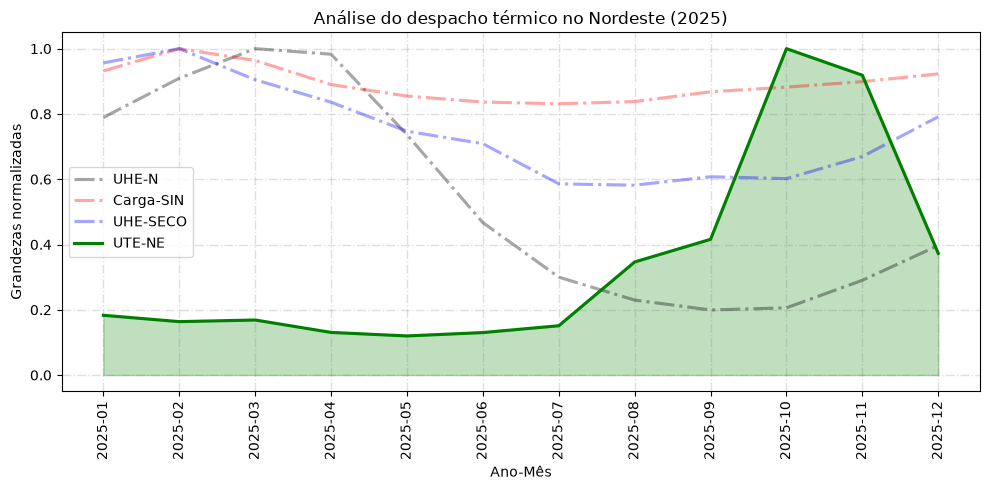

In [7]:
# # Análise da variação da geração térmica no Nordeste: ano de 2025
# # Gráficos de linhas (plot - UHE-N, Carga-SIN, UHE-SECO) + área (fill_between - UTE-NE)

plt.figure(figsize=(10,5))

aux_N = dados_N_mensal[dados_N_mensal["Ano"] == 2025]
aux_SIN = dados_SIN_mensal[dados_SIN_mensal["Ano"] == 2025]
aux_SE = dados_SE_mensal[dados_SE_mensal["Ano"] == 2025]
aux_NE = dados_NE_mensal[dados_NE_mensal["Ano"] == 2025]

plt.plot(
    aux_N["Ano-Mes"],
    aux_N["UHE"]/aux_N["UHE"].max(),
    color="black",
    linewidth=2.25,
    linestyle="-.",
    label="UHE-N",
    alpha=0.35
)
plt.plot(
    aux_SIN["Ano-Mes"],
    aux_SIN["Carga"]/aux_SIN["Carga"].max(),
    color="red",
    linewidth=2.25,
    linestyle="-.",
    label="Carga-SIN",
    alpha=0.35
)
plt.plot(
    aux_SE["Ano-Mes"],
    aux_SE["UHE"]/aux_SE["UHE"].max(),
    color="blue",
    linewidth=2.25,
    linestyle="-.",
    label="UHE-SECO",
    alpha=0.35
)

plt.plot(
    aux_NE["Ano-Mes"],
    aux_NE["UTE"]/aux_NE["UTE"].max(),
    color="green",
    linewidth=2.25,
    linestyle="-",
    label="UTE-NE"
)
plt.fill_between(
    aux_NE["Ano-Mes"],
    aux_NE["UTE"] / aux_NE["UTE"].max(),
    color="green",
    alpha=0.25
)

# Grid
plt.grid(
    color="grey",
    linestyle="-.",
    linewidth=1.0,
    alpha=0.25
)

# Evitar margem branca vertical no gráfico (colar as áreas nos eixos)
ax.margins(x=0)
ax.margins(y=0)

# Eixos e títulos
# plt.yticks(range(-9000, 12001, 3000)) # min / max / intervalo
plt.xlabel("Ano-Mês")
plt.ylabel("Grandezas normalizadas")
plt.title("Análise do despacho térmico no Nordeste (2025)")
plt.xticks(rotation=90)
plt.legend()

plt.tight_layout()
plt.show()

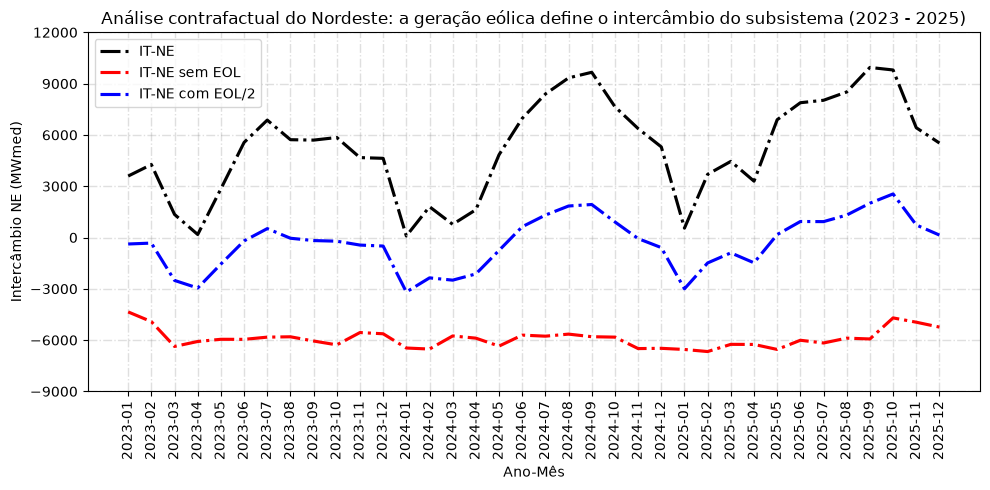

In [8]:
# # Análise contrafactual do Nordeste: a geração eólica define o intercâmbio do subsistema
# # Gráficos de linhas de cada cenário: IT-NE, IT-NE sem EOL e IT-NE com EOL/2

# Matriz do NE, sem geração eólica
dados_NE_mensal["UHE+UTE+UFV"] = dados_NE_mensal["UHE"] + dados_NE_mensal["UTE"] + dados_NE_mensal["UFV"]

plt.figure(figsize=(10,5))

plt.plot(
    dados_NE_mensal["Ano-Mes"],
    dados_NE_mensal["Intercambio"],
    color="black",
    linewidth=2.25,
    linestyle="-.",
    label="IT-NE"
)
# Cenário sem geração eólica - IT-NE sem EOL
plt.plot(
    dados_NE_mensal["Ano-Mes"],
    dados_NE_mensal["UHE+UTE+UFV"] - dados_NE_mensal["Carga"],
    color="red",
    linewidth=2.25,
    linestyle="-.",
    label="IT-NE sem EOL"
)
# Cenário com metade da geração eólica - IT-NE com EOL/2
plt.plot(
    dados_NE_mensal["Ano-Mes"],
    dados_NE_mensal["UHE+UTE+UFV"] + dados_NE_mensal["EOL"]/2 - dados_NE_mensal["Carga"],
    color="blue",
    linewidth=2.25,
    linestyle="-.",
    label="IT-NE com EOL/2"
)

# Grid
plt.grid(
    color="grey",
    linestyle="-.",
    linewidth=1.0,
    alpha=0.25
)

# Evitar margem branca vertical no gráfico (colar as áreas nos eixos)
ax.margins(x=0)
ax.margins(y=0)

# Eixos e títulos
plt.yticks(range(-9000, 12001, 3000)) # min / max / intervalo
plt.xlabel("Ano-Mês")
plt.ylabel("Intercâmbio NE (MWmed)")
plt.title("Análise contrafactual do Nordeste: a geração eólica define o intercâmbio do subsistema (2023 - 2025)")
plt.xticks(rotation=90)
plt.legend()

plt.tight_layout()
plt.show()

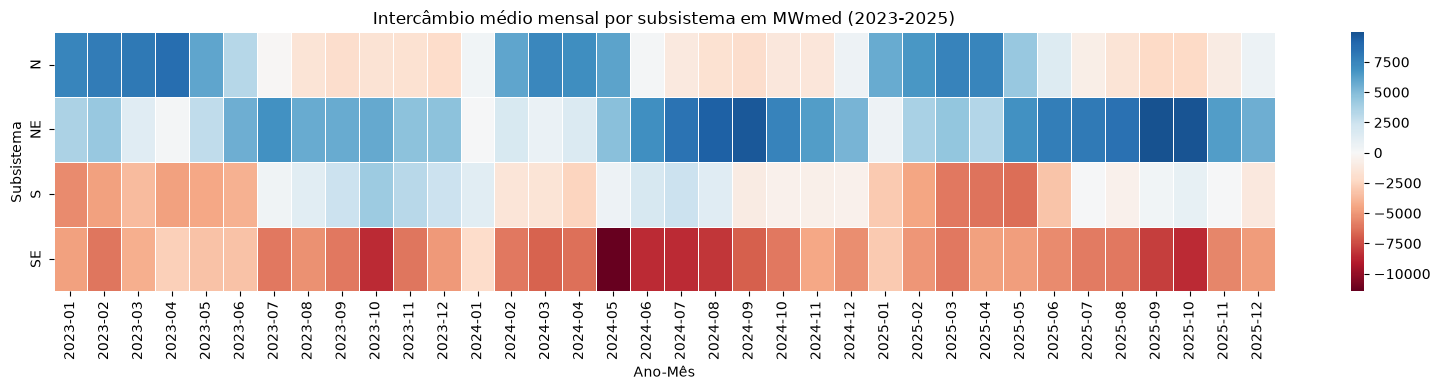

In [9]:
# # Análise do intercâmbio médio mensal por subsistema
# # Mapa de calor (heatmap) do intercâmbio médio mensal por subsistema

df_heat = pd.concat([
    dados_NE_mensal.assign(SME="NE"),
    dados_N_mensal.assign(SME="N"),
    dados_S_mensal.assign(SME="S"),
    dados_SE_mensal.assign(SME="SE")
])

df_heat["Ano-Mes"] = (
    df_heat["Ano"].astype(str)
    + "-"
    + df_heat["Mes"].astype(str).str.zfill(2)
)

pivot = df_heat.pivot(
    index="SME",
    columns="Ano-Mes",
    values="Intercambio"
)

# Dados do gráfico
plt.figure(figsize=(16,4))

sns.heatmap(
    pivot,
    cmap="RdBu",
    center=0,
    linewidths=0.5
)

# Eixos e títulos
plt.title("Intercâmbio médio mensal por subsistema em MWmed (2023-2025)")
plt.xlabel("Ano-Mês")
plt.ylabel("Subsistema")

plt.tight_layout()
plt.show()

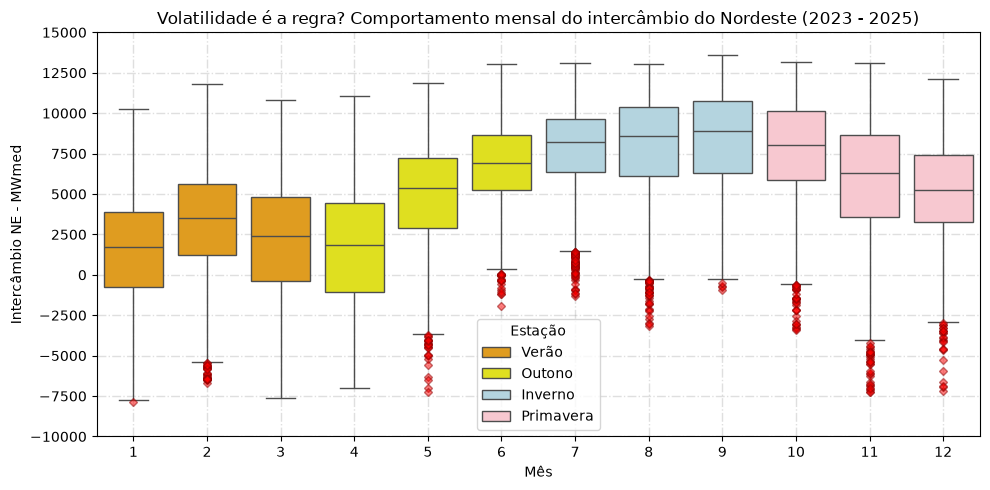

In [10]:
# # Análise da sazonalidade e volatilidade do intercâmbio médio mensal do Nordeste
# # Boxplot do intercâmbio médio mensal do Nordeste por estação do ano (cor da caixa)

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=dados_NE,
    x="Mes",
    y="Intercambio",
    hue="Estacao",
    palette={
        "Verão": "orange",
        "Outono": "yellow",
        "Inverno": "lightblue",
        "Primavera": "pink"
    },
    flierprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "darkred",
        "markersize": 4,
        "alpha": 0.5
    }
)

# Grid
plt.grid(
    color="grey",
    linestyle="-.",
    linewidth=1.0,
    alpha=0.25
)

# Eixos e títulos
plt.yticks(range(-10000, 15001, 2500)) # min / max / intervalo
plt.xlabel("Mês")
plt.ylabel("Intercâmbio NE - MWmed")
plt.title("Volatilidade é a regra? Comportamento mensal do intercâmbio do Nordeste (2023 - 2025)")
plt.legend(title="Estação", loc="lower center")

plt.tight_layout()
plt.show()

count    26304.000000
mean      5259.092088
std       4087.535515
min      -7872.617000
25%       2591.292250
50%       5748.734000
75%       8326.952750
max      13591.512000
Name: Intercambio, dtype: float64


Ano   Estacao  
2023  Inverno      31
      Outono       15
      Primavera    26
      Verão         3
2024  Inverno      78
      Outono       30
      Primavera    46
      Verão         5
2025  Inverno      72
      Outono       44
      Primavera    42
      Verão        10
Name: CarregaBESS, dtype: int64


Ano   Estacao  
2023  Inverno      92
      Outono       91
      Primavera    92
      Verão        90
2024  Inverno      92
      Outono       91
      Primavera    92
      Verão        91
2025  Inverno      92
      Outono       91
      Primavera    92
      Verão        90
dtype: int64


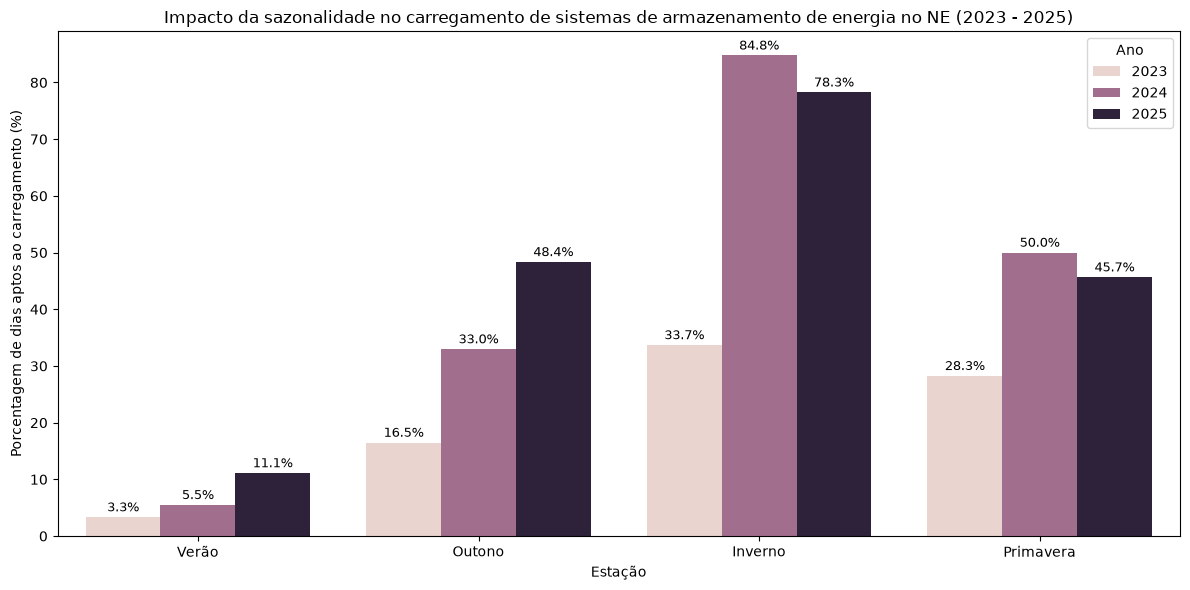

In [11]:
# # Distribuição do Intercâmbio do NE: por quantas horas o NE operou em cada faixa de intercâmbio (MWmed)
# # Tratamento específico para os dados do NE
# Cálculo da mediana e quartis do intercâmbio do NE
descricao_intercambio = dados_NE["Intercambio"].describe()
print(dados_NE["Intercambio"].describe()) # debug
print("\n")
# Definição do limiar para classificação de intercâmbio elevado (3º quartil)
limiar = descricao_intercambio["75%"] # 3º quartil

# Classificação de intercâmbio como candidato a dia de exportação elevada
dados_NE["Perfil_Intercambio"] = dados_NE["Intercambio"].apply(lambda x: 1 if x >= limiar else 0)
# print(dados_NE["Perfil_Intercambio"].value_counts()) # debug

# Classificação do horário típico de excedente energético
dados_NE["Excedente"] = dados_NE["Hora"].apply(lambda x: 1 if (x >= 5 and x < 17) else 0)
# print(dados_NE.head(17)) # debug


# A condição de carregamento do BESS exige simultaneamente:
# 1) Período com potencial excedente energético (05h às 16h)
# 2) Intercâmbio elevado (acima do 3° quartil)
dados_NE["CondicaoBESS"] = (
    (dados_NE["Excedente"] == 1)
    & (dados_NE["Perfil_Intercambio"] == 1)
).astype(int)

# Inicializa a coluna que indicará se o dia é candidato ao carregamento do BESS
dados_NE["CarregaBESS"] = 0

# Avalia cada dia de forma independente
for data, grupo in dados_NE.groupby("Data"):
       # Monta a janela de 4 horas para identificar se há 4 horas consecutivas de excedente energético e intercâmbio elevado
       teste = (
              grupo["CondicaoBESS"]
              .rolling(window=4)
              .sum()
       )
       # Avalia se houve 4 horas consecutivas de excedente energético e intercâmbio elevado
       if (teste >= 4).any():
              # Caso exista pelo menos uma sequência válida de 4 horas, o dia é marcado como elegível ao carregamento do BESS
              dados_NE.loc[
                     dados_NE["Data"] == data,
                     "CarregaBESS"
              ] = 1

# Consolida o indicador em base diária
# Mantém a estação do ano e o resultado final de carregamento para cada dia
dados_NE_BESS = (
    dados_NE
    .groupby(["Data", "Ano"])[["CarregaBESS", "Estacao"]]
    .max()
    .reset_index()
)

# Debug: contabiliza quantos dias foram classificados como aptos ao carregamento do BESS
# por ano e por estação do ano
print(
    dados_NE_BESS
    .groupby(["Ano", "Estacao"])["CarregaBESS"]
    .sum()
)
print("\n")
print(
    dados_NE_BESS
    .groupby(["Ano", "Estacao"])
    .size()
)

#-----

resumo = (
    dados_NE_BESS
    .groupby(["Ano","Estacao"])
    .agg(
        Dias_Carrega=("CarregaBESS","sum"),
        Total_Dias=("CarregaBESS","count")
    )
)

resumo["Pct"] = (
    100 * resumo["Dias_Carrega"]
    / resumo["Total_Dias"]
)

fig, ax = plt.subplots(figsize=(12,6))

sns.barplot(
    data=resumo.reset_index(),
    x="Estacao",
    y="Pct",
    hue="Ano",
    order=[
        "Verão",
        "Outono",
        "Inverno",
        "Primavera"
    ],
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        fontsize=9,
        padding=2
    )

plt.xlabel("Estação")
plt.ylabel("Porcentagem de dias aptos ao carregamento (%)")
plt.title("Impacto da sazonalidade no carregamento de sistemas de armazenamento de energia no NE (2023 - 2025)")
plt.tight_layout()
plt.show()

In [12]:
# Gera o arquivo requirements.txt com as dependências do projeto
!pip freeze > requirements.txt